In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "02_E0.6_rq1_theo_thang_mua_xu_huong_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:01:38 | INFO | Bắt đầu chạy 02_E0.6_rq1_theo_thang_mua_xu_huong_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0001_02_E0.6_rq1_theo_thang_mua_xu_huong_Han.log


# E0.6 – RQ1: theo tháng, mùa và xu hướng dài hạn

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.6 – RQ1: theo tháng, mùa và xu hướng dài hạn |
| **Mục đích** | Tách từ `02_eda.ipynb`: RQ1 (c), (d) (mục 5, 6). |
| **Đọc vào** | `data/processed/hourly_clean.csv` (do `01_cleaning` tạo) |
| **Ghi ra** | `data/eda_data/eda_rq1_theo_thang_mua.csv`, `data/eda_data/eda_rq1_theo_nam.csv`, `data/eda_data/eda_rq1_theo_thang_chuoi.csv`, `figures/eda_figures/02_rq1_theo_thang_mua.*`, `figures/eda_figures/02_rq1_xu_huong.*` |
| **Chạy sau** | `01_cleaning.ipynb` (cần `hourly_clean.csv`) |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda_notebooks/
FILE = ROOT / "data" / "processed" / "hourly_clean.csv"
DIR_DATA = ROOT / "data" / "eda_data"
DIR_FIG = ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "svg.fonttype": "none"})

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
VAR_RQ2 = ["Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

DOW_LABEL = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
PERIOD_LABEL = {1: "Năm 1\n12/2006–11/2007", 2: "Năm 2\n12/2007–11/2008",
                3: "Năm 3\n12/2008–11/2009", 4: "Năm 4\n12/2009–11/2010"}

def season_of(m):
    """Mùa theo khí hậu Pháp (bắc bán cầu): Đông 12-2, Xuân 3-5, Hè 6-8, Thu 9-11."""
    if m in (12, 1, 2): return "Đông"
    if m in (3, 4, 5): return "Xuân"
    if m in (6, 7, 8): return "Hè"
    return "Thu"

def vn(x, d=3):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def strength(r):
    a = abs(r)
    if a >= 0.7: return "mạnh"
    if a >= 0.4: return "trung bình"
    if a >= 0.2: return "yếu"
    return "rất yếu"

def save_fig(name):
    plt.savefig(DIR_FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(DIR_FIG / f"{name}.svg", bbox_inches="tight")

notes = []   # các câu gợi ý nhận xét (số liệu tự điền)
def add_note(tag, text):
    notes.append(f"- **[{tag}]** {text}")

In [3]:
raw = pd.read_csv(FILE, parse_dates=["datetime"], index_col="datetime")
assert (raw.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "Trục giờ không liên tục"

df = raw[COLS].copy()                       # chỉ 7 cột gốc, không dùng *_ffill
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek              # 0 = thứ 2 ... 6 = chủ nhật
df["is_weekend"] = df["dow"] >= 5
df["month"] = df.index.month
df["season"] = df["month"].map(season_of)
# Năm vận hành: tháng 12 đến tháng 11 năm sau (khớp với khoảng dữ liệu 12/2006 đến 11/2010)
df["period"] = np.asarray(((df.index.year * 12 + df.index.month) - (2006 * 12 + 12)) // 12 + 1)

n_all = len(df)
n_valid = int(df[TARGET].notna().sum())
print(f"Tổng số giờ: {fmt(n_all)} | Giờ có số đo thật: {fmt(n_valid)} | Giờ thiếu (bỏ qua): {fmt(n_all - n_valid)}")
print("Khoảng thời gian:", df.index[0], "->", df.index[-1])
print("Số giờ có số đo theo mùa:\n", df.groupby("season")[TARGET].count().reindex(SEASON_ORDER))
df.head()

Tổng số giờ: 34.588 | Giờ có số đo thật: 34.157 | Giờ thiếu (bỏ qua): 431
Khoảng thời gian: 2006-12-16 17:00:00 -> 2010-11-26 20:00:00
Số giờ có số đo theo mùa:
 season
Xuân    8736
Hè      8639
Thu     8549
Đông    8233
Name: Global_active_power, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,is_weekend,month,season,period
datetime,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,17,5,True,12,Đông,1
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,18,5,True,12,Đông,1
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,19,5,True,12,Đông,1
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,20,5,True,12,Đông,1
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,21,5,True,12,Đông,1


In [4]:
MA_TN = "E0.6"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.6

## 5. RQ1 (c): Theo tháng và mùa
Mùa theo khí hậu Pháp (Đông: 12–2, Xuân: 3–5, Hè: 6–8, Thu: 9–11). Mỗi tháng dương lịch xuất hiện đúng 4 lần trong dữ liệu (12/2006–11/2010) nên trung bình theo tháng và mùa cân bằng giữa các năm.

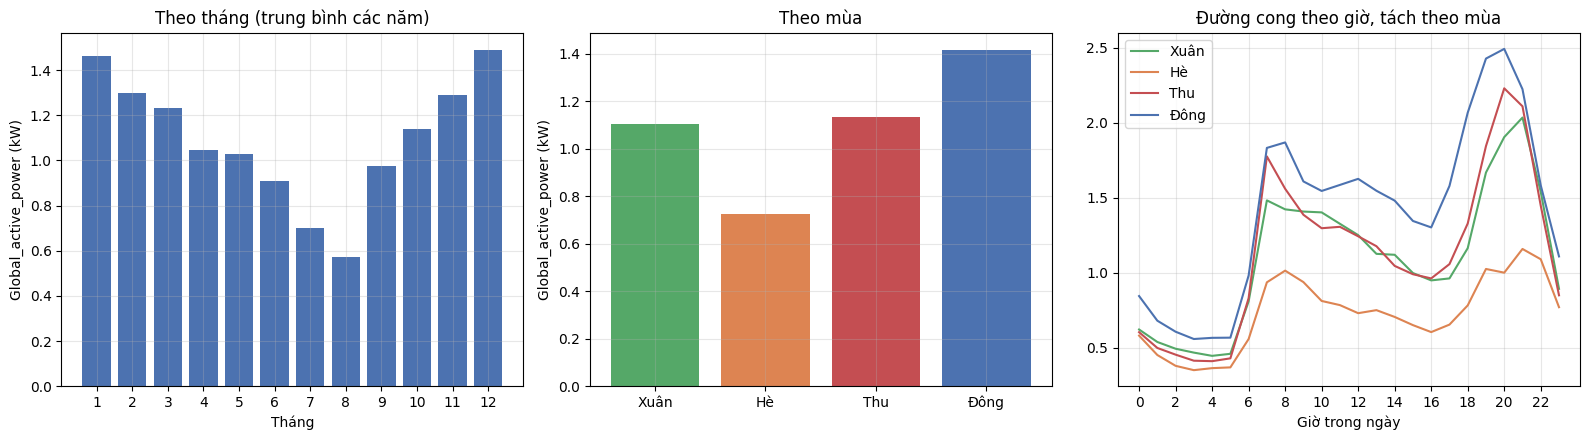

,mean,std,count,nhom
Tháng 1,1.462,1.045,2924,thang
Tháng 2,1.300,1.009,2711,thang
Tháng 3,1.231,0.929,2942,thang
Tháng 4,1.047,0.819,2818,thang
Tháng 5,1.030,0.757,2976,thang
Tháng 6,0.909,0.705,2824,thang
Tháng 7,0.700,0.567,2974,thang
Tháng 8,0.573,0.591,2841,thang
Tháng 9,0.976,0.776,2793,thang
Tháng 10,1.137,0.891,2975,thang


In [5]:
mth = df.groupby("month")[TARGET].agg(["mean", "std", "count"])
ses = df.groupby("season")[TARGET].agg(["mean", "std", "count"]).reindex(SEASON_ORDER)
prof_season = df.groupby(["hour", "season"])[TARGET].mean().unstack()[SEASON_ORDER]

tbl = pd.concat([
    mth.rename(index=lambda m: f"Tháng {m}").assign(nhom="thang"),
    ses.rename(index=lambda s_: f"Mùa {s_}").assign(nhom="mua"),
])
tbl.round(4).to_csv(DIR_DATA / "eda_rq1_theo_thang_mua.csv", index_label="ten")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].bar(mth.index, mth["mean"], color="#4C72B0")
ax[0].set_xticks(range(1, 13)); ax[0].set_title("Theo tháng (trung bình các năm)")
ax[0].set_xlabel("Tháng"); ax[0].set_ylabel("Global_active_power (kW)")
ax[1].bar(ses.index, ses["mean"], color=["#55A868", "#DD8452", "#C44E52", "#4C72B0"])
ax[1].set_title("Theo mùa"); ax[1].set_ylabel("Global_active_power (kW)")
for c, col in zip(SEASON_ORDER, ["#55A868", "#DD8452", "#C44E52", "#4C72B0"]):
    ax[2].plot(prof_season.index, prof_season[c], label=c, color=col)
ax[2].set_title("Đường cong theo giờ, tách theo mùa")
ax[2].set_xlabel("Giờ trong ngày"); ax[2].set_xticks(range(0, 24, 2)); ax[2].legend()
plt.tight_layout()
save_fig("02_rq1_theo_thang_mua")
plt.show()
tbl.round(3)

In [6]:
hi_m, lo_m = int(mth["mean"].idxmax()), int(mth["mean"].idxmin())
add_note("RQ1-mùa", f"Tháng có công suất trung bình cao nhất là tháng {hi_m} ({vn(mth.loc[hi_m, 'mean'])} kW), thấp nhất là tháng {lo_m} ({vn(mth.loc[lo_m, 'mean'])} kW).")
hi_s, lo_s = ses["mean"].idxmax(), ses["mean"].idxmin()
add_note("RQ1-mùa", "Trung bình theo mùa: " + "; ".join(f"{k} {vn(v)} kW" for k, v in ses["mean"].items()) +
         f". Mùa cao nhất là {hi_s}, thấp nhất là {lo_s}, chênh nhau {vn((ses.loc[hi_s, 'mean'] / ses.loc[lo_s, 'mean'] - 1) * 100, 1)}%.")
dh_win = prof_season["Đông"] - prof_season["Hè"]
add_note("RQ1-mùa", f"Giữa mùa Đông và mùa Hè, chênh lệch theo giờ lớn nhất lúc {int(dh_win.abs().idxmax())}h "
         f"(Đông {vn(prof_season.loc[int(dh_win.abs().idxmax()), 'Đông'])} kW, Hè {vn(prof_season.loc[int(dh_win.abs().idxmax()), 'Hè'])} kW).")

**Nhận xét:** Tháng 12 cao nhất (1,490 kW), tháng 8 thấp nhất (0,573 kW). Theo mùa: Đông 1,418 kW; Thu 1,135; Xuân 1,103; Hè 0,727, tức mùa Đông cao hơn mùa Hè khoảng 95%. Chênh lệch lớn nhất lúc 20h (Đông 2,493 kW, Hè 1,000 kW), nên cần đặc trưng tháng (sin/cos) để mô hình nắm được chu kỳ năm.

## 6. RQ1 (d): Xu hướng dài hạn
- Chuỗi trung bình theo tháng. Vòng tròn đỏ rỗng là tháng có ít hơn 90% số giờ đo được (do các khoảng thiếu), nên giá trị trung bình kém tin cậy hơn.
- Trung bình theo "năm vận hành" (tháng 12 đến tháng 11). Lưu ý tháng 12/2006 chỉ bắt đầu từ ngày 16 và tháng 11/2010 kết thúc ngày 26.

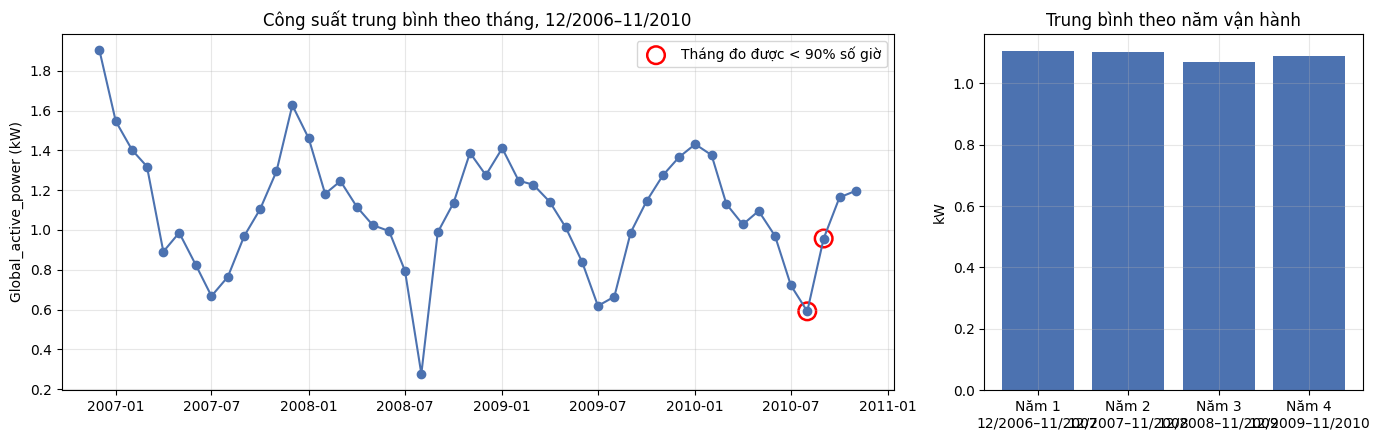

Số tháng đo được < 90% số giờ: 2


,mean,std,count,so_voi_nam_1_%
period,,,,
1,1.106,0.994,8318,0.000
2,1.102,0.944,8783,-0.379
3,1.071,0.838,8688,-3.177
4,1.088,0.802,8368,-1.633


In [7]:
mon = df[TARGET].resample("MS").agg(["mean", "count"])
mon["so_gio_luoi"] = df[TARGET].resample("MS").size()
mon["ty_le_do_duoc"] = mon["count"] / mon["so_gio_luoi"]
low_cov = mon[mon["ty_le_do_duoc"] < 0.90]

per = df.groupby("period")[TARGET].agg(["mean", "std", "count"])
per["so_voi_nam_1_%"] = (per["mean"] / per.loc[1, "mean"] - 1) * 100
per.round(4).to_csv(DIR_DATA / "eda_rq1_theo_nam.csv", index_label="nam_van_hanh")
mon.round(4).to_csv(DIR_DATA / "eda_rq1_theo_thang_chuoi.csv", index_label="thang")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(mon.index, mon["mean"], marker="o", color="#4C72B0")
ax[0].scatter(low_cov.index, low_cov["mean"], s=160, facecolors="none", edgecolors="red", linewidths=1.8,
              label="Tháng đo được < 90% số giờ")
ax[0].set_title("Công suất trung bình theo tháng, 12/2006–11/2010")
ax[0].set_ylabel("Global_active_power (kW)"); ax[0].legend()
ax[1].bar([PERIOD_LABEL[i] for i in per.index], per["mean"], color="#4C72B0")
ax[1].set_title("Trung bình theo năm vận hành"); ax[1].set_ylabel("kW")
plt.tight_layout()
save_fig("02_rq1_xu_huong")
plt.show()
print("Số tháng đo được < 90% số giờ:", len(low_cov))
per.round(3)

In [8]:
add_note("RQ1-xu hướng", "Trung bình theo năm vận hành (tháng 12 đến tháng 11): " +
         "; ".join(f"năm {i} {vn(r['mean'])} kW" for i, r in per.iterrows()) +
         f". Năm 4 so với năm 1: {'cao hơn' if per.loc[4, 'so_voi_nam_1_%'] > 0 else 'thấp hơn'} {vn(abs(per.loc[4, 'so_voi_nam_1_%']), 1)}%.")
add_note("RQ1-xu hướng", f"Có {len(low_cov)} tháng đo được dưới 90% số giờ (cần thận trọng khi đọc giá trị các tháng này): "
         + (", ".join(m.strftime("%m/%Y") for m in low_cov.index) if len(low_cov) else "không có") + ".")

**Nhận xét:** Trung bình theo năm vận hành gần như không đổi: 1,106; 1,102; 1,071; 1,088 kW; năm 4 thấp hơn năm 1 chỉ 1,6%. Không thấy xu hướng dài hạn rõ rệt, nên chia Train và Test theo thời gian không làm lệch mức tiêu thụ giữa hai tập. Hai tháng 08/2010 và 09/2010 đo được dưới 90% số giờ nên cần đọc thận trọng.

## Gợi ý nhận xét E0.6 (số tự điền)

In [9]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 00:01:39 | INFO | Gợi ý nhận xét E0.6 (số tự điền), lưu ở data/eda_E0.6_goi_y_nhan_xet.md:
- **[RQ1-mùa]** Tháng có công suất trung bình cao nhất là tháng 12 (1,490 kW), thấp nhất là tháng 8 (0,573 kW).
- **[RQ1-mùa]** Trung bình theo mùa: Xuân 1,103 kW; Hè 0,727 kW; Thu 1,135 kW; Đông 1,418 kW. Mùa cao nhất là Đông, thấp nhất là Hè, chênh nhau 95,1%.
- **[RQ1-mùa]** Giữa mùa Đông và mùa Hè, chênh lệch theo giờ lớn nhất lúc 20h (Đông 2,493 kW, Hè 1,000 kW).
- **[RQ1-xu hướng]** Trung bình theo năm vận hành (tháng 12 đến tháng 11): năm 1 1,106 kW; năm 2 1,102 kW; năm 3 1,071 kW; năm 4 1,088 kW. Năm 4 so với năm 1: thấp hơn 1,6%.
- **[RQ1-xu hướng]** Có 2 tháng đo được dưới 90% số giờ (cần thận trọng khi đọc giá trị các tháng này): 08/2010, 09/2010.


## Log lên W&B (minh chứng)

In [10]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = ['eda_rq1_theo_thang_mua.csv', 'eda_rq1_theo_nam.csv', 'eda_rq1_theo_thang_chuoi.csv']
    HINH = ['02_rq1_theo_thang_mua.png', '02_rq1_xu_huong.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.6-Han-rq1-theo-thang-mua-xu-huong", tags=["E0.6", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in notes[moc_note:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run 9mi1biar


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000140-9mi1biar
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.6-Han-rq1-theo-thang-mua-xu-huong


... (8 outputs left out)

wandb: uploading artifact run-9mi1biar-bangeda_rq1_theo_thang_mua-2PzxkA; uploading artifact run-9mi1biar-bangeda_rq1_theo_nam-RYRmSQ; uploading media/images/hinh/02_rq1_theo_thang_mua_0_f167573167def87bfa59.png


wandb: uploading history steps 0-0, summary, console lines 0-0


wandb: 🚀 View run ck-E0.6-Han-rq1-theo-thang-mua-xu-huong at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/9mi1biar
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 6 media file(s), 6 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000140-9mi1biar/logs


## Nhật ký

- 01/11/2026 – Viết lần đầu trong notebook `02_eda.ipynb`. Commit `74a9949`.
- 07/11/2026 – Sửa `02_eda.ipynb`. Commit `9a1f293`, `910a450`.
- 13/11/2026 – Tách RQ1 (c), (d) (mục 5, 6) ra khỏi `02_eda.ipynb` thành notebook riêng `02_E0.6_rq1_theo_thang_mua_xu_huong_Han.ipynb`, thêm ô ghi log. Commit `cdf1bfd` (lúc này notebook chưa chạy).
- 13/11/2026 – Chạy lúc 19:59, commit log và bảng kết quả. Commit `3833137`.
- 13/11/2026 – Lưu notebook có output (commit trước chưa kèm notebook đã chạy). Commit `a3bdc6e`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.